In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay, classification_report
from src.iqr import IQRCapper

# Global config
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Cont
RANDOM_KEY = 26

# Définir les colonnes
NUMERIC_COLS = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

NOMINAL_COLS = [
    "Gender",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

ORDINAL_COLS = [
    "Year_of_Study",
    "Physical_Activity",
    "Diet_Quality"
]

# Étape 1 — Chargement et Analyse exploratoire des données

## 1 - Chargement et compréhension du Dataset

#### 1-1 Chargement des données

In [23]:
def load_data_frame(path:str):
    return pd.read_csv(path)

df = load_data_frame('../data/row.csv')

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


#### 1-2 Dimensions du Dataset

In [24]:
print('Nomber des lignes :', df.shape[0])
print('Nomber des colonnes :', df.shape[1])

Nomber des lignes : 2000
Nomber des colonnes : 17


#### 1-3 Types de données

In [25]:
df.info()
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

#### 1-4 Vérifier les catégories

In [26]:
for col in ORDINAL_COLS + NOMINAL_COLS:
    print(f'=== {col} ===')
    print(df[col].value_counts(), '\n')


=== Year_of_Study ===
Year_of_Study
1    509
2    500
3    426
4    352
5    213
Name: count, dtype: int64 

=== Physical_Activity ===
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64 

=== Diet_Quality ===
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64 

=== Gender ===
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64 

=== Part_Time_Job ===
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64 

=== Previous_Mental_Health_History ===
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64 



## 2 - Vérification de la qualité des données

#### 2-1 Valeurs manquantes

               column  Count  Percentage
0    Financial_Stress     91        4.55
1        Diet_Quality     69        3.45
2         Sleep_Hours     62        3.10
3  Social_Media_Hours     58        2.90
4      Family_Support     54        2.70
5     Attendance_Rate     47        2.35
6                 GPA     38        1.90


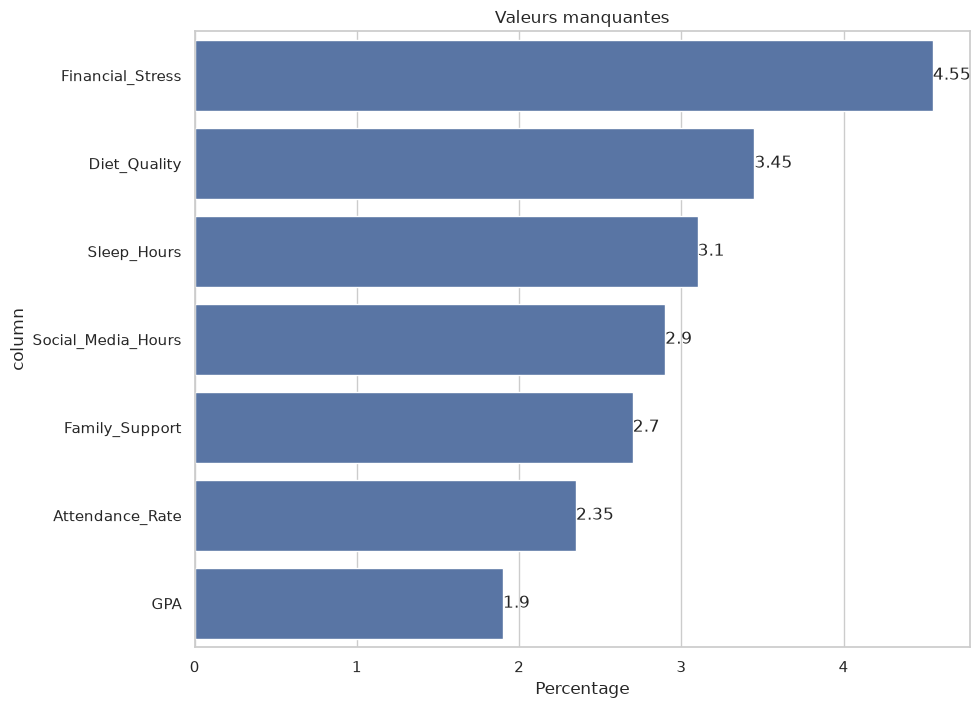

In [27]:
missing_report = pd.DataFrame({
    "Count": df.isna().sum(),
    "Percentage": (df.isna().mean() * 100).round(2)
})

missing_report = missing_report[missing_report['Percentage'] > 0].sort_values(by='Percentage', ascending=False)

missing_report = missing_report.reset_index(names='column')

print(missing_report)

plt.figure(figsize=(10, 8))
ax = sns.barplot(data=missing_report, x='Percentage', y='column')

for container in ax.containers:
    ax.bar_label(container)

plt.title("Valeurs manquantes")
plt.show()

#### Doublons

In [28]:
print('Nomber Doublons :', df.duplicated().sum())

Nomber Doublons : 0


#### 2-2 Incohérences

In [29]:
rules = {
    "Age": (0, 30),
    "Sleep_Hours": (0, 24),
    "Study_Hours_Per_Week": (0, 168),
    "Social_Media_Hours": (0, 24),
    "Screen_Time_Hours": (0, 24),
    "Attendance_Rate": (0, 100),
}

for col, (min,max) in rules.items():
    invalid = df[col].notna() & ~df[col].between(min, max)
    print(f'{col}: {invalid.sum()} valeurs invalides')


print("La somme des lines avec Social_Media_Hours > Screen_Time_Hours:", df[df['Social_Media_Hours'] > df['Screen_Time_Hours']].shape[0])

Age: 0 valeurs invalides
Sleep_Hours: 0 valeurs invalides
Study_Hours_Per_Week: 0 valeurs invalides
Social_Media_Hours: 0 valeurs invalides
Screen_Time_Hours: 0 valeurs invalides
Attendance_Rate: 0 valeurs invalides
La somme des lines avec Social_Media_Hours > Screen_Time_Hours: 37


#### 2-3 Valeurs aberrantes

In [30]:
outlier_report = []

for col in NUMERIC_COLS:
    Q1, Q3 = df[col].quantile([0.25, 0.75])

    IQR = Q3 -Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[col].notna() & ((df[col] < lower) | (df[col] > upper))
    outlier_report.append({
        'Column': col,
        'Outliers': outliers.sum(),
        'lower': lower,
        'upper': upper
    })

pd.DataFrame(outlier_report)

,Column,Outliers,lower,upper
0,Age,4,15.5000,27.5000
1,Sleep_Hours,2,3.6000,10.0000
2,Study_Hours_Per_Week,7,4.0000,36.0000
3,GPA,9,1.6150,3.4950
4,Social_Media_Hours,20,3.0125,8.9125
5,Screen_Time_Hours,7,3.9500,13.1500
6,Financial_Stress,0,0.1500,11.7500
7,Family_Support,0,0.7500,12.3500
8,Attendance_Rate,12,65.7500,104.5500


## 3 - Statistiques descriptives

#### 3-1 Variables numériques

In [31]:
df[NUMERIC_COLS].describe().T # Transpose

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


#### 3-2 Histograms & Boxplots (Analyse univariée) pour les numerci colonnes

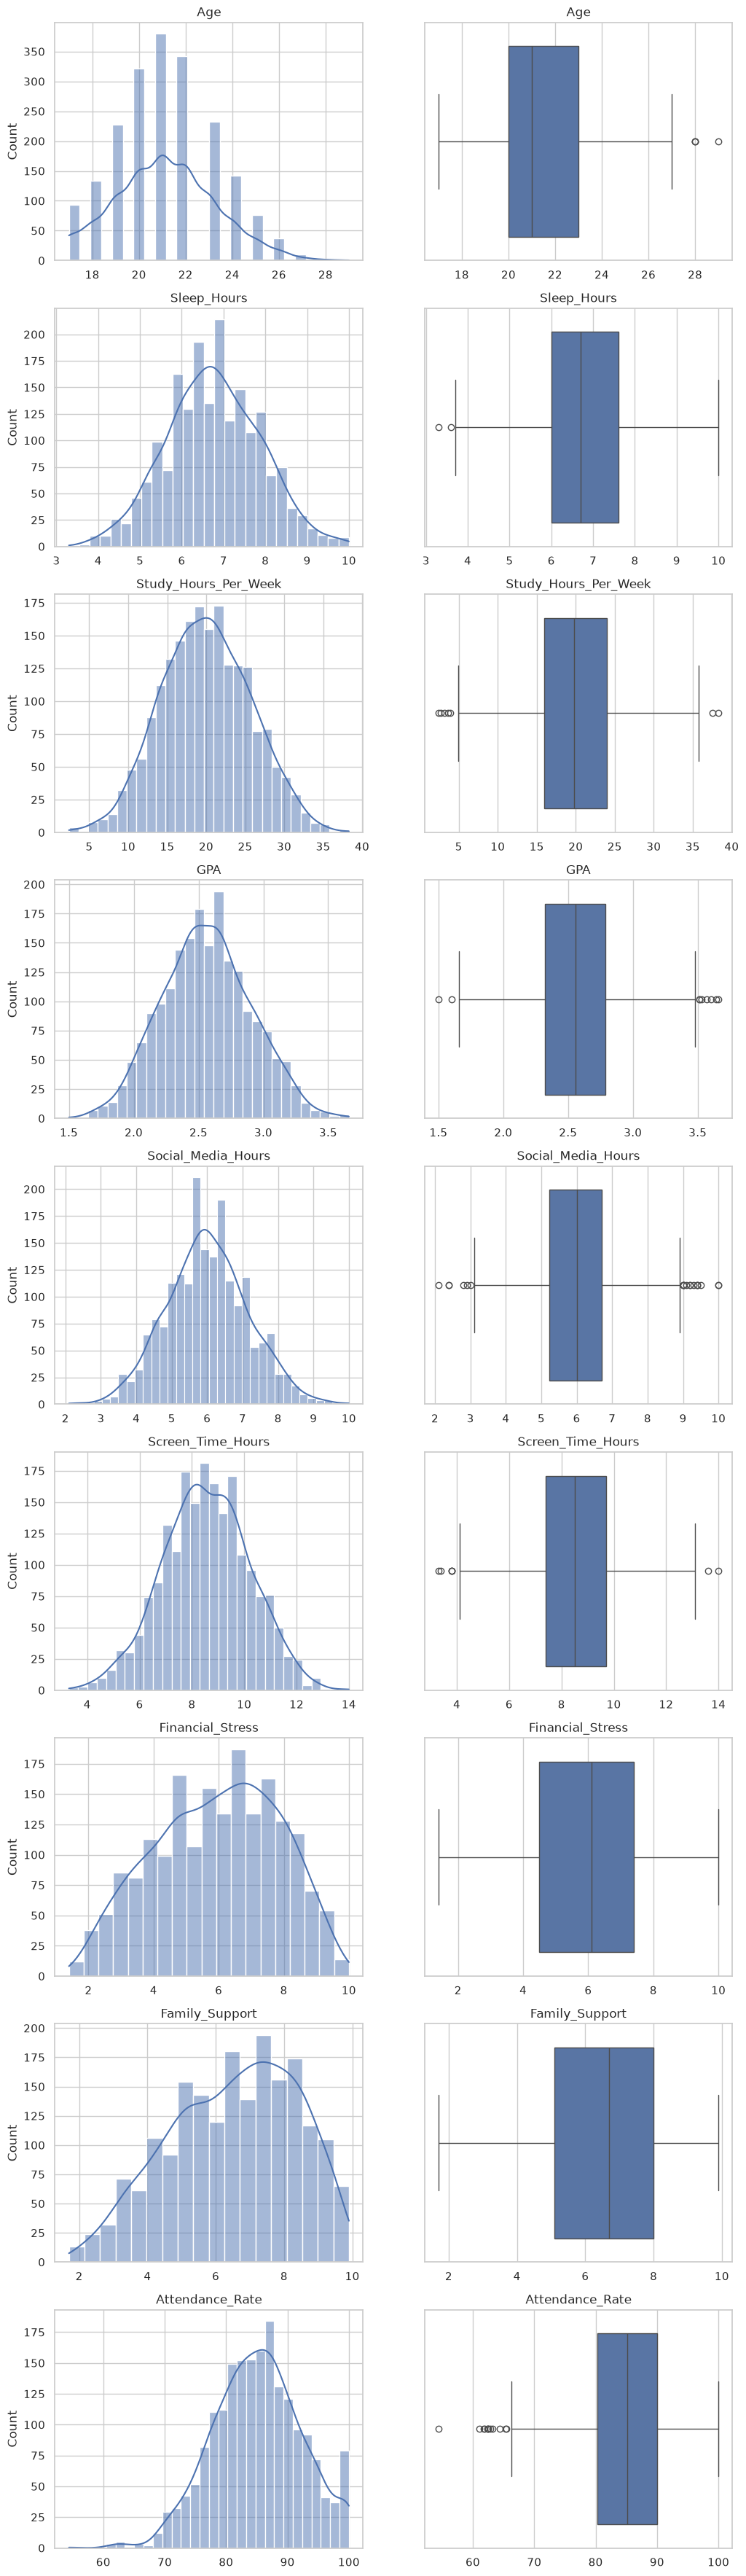

In [32]:
_, axes = plt.subplots(nrows=len(NUMERIC_COLS), ncols=2, figsize=(12, 5 * len(NUMERIC_COLS)))

for index, col in enumerate(NUMERIC_COLS):
    # Histogram
    sns.histplot(data=df, x=col, kde=True,ax = axes[index, 0])
    axes[index, 0].set_title(col)
    axes[index, 0].set_xlabel('')

    # Boxplot
    sns.boxplot(data=df, x=col, ax=axes[index, 1])
    axes[index, 1].set_title(col)
    axes[index, 1].set_xlabel('')

plt.show()

#### 3-3 Variables catégorielles (Analyse univariée)

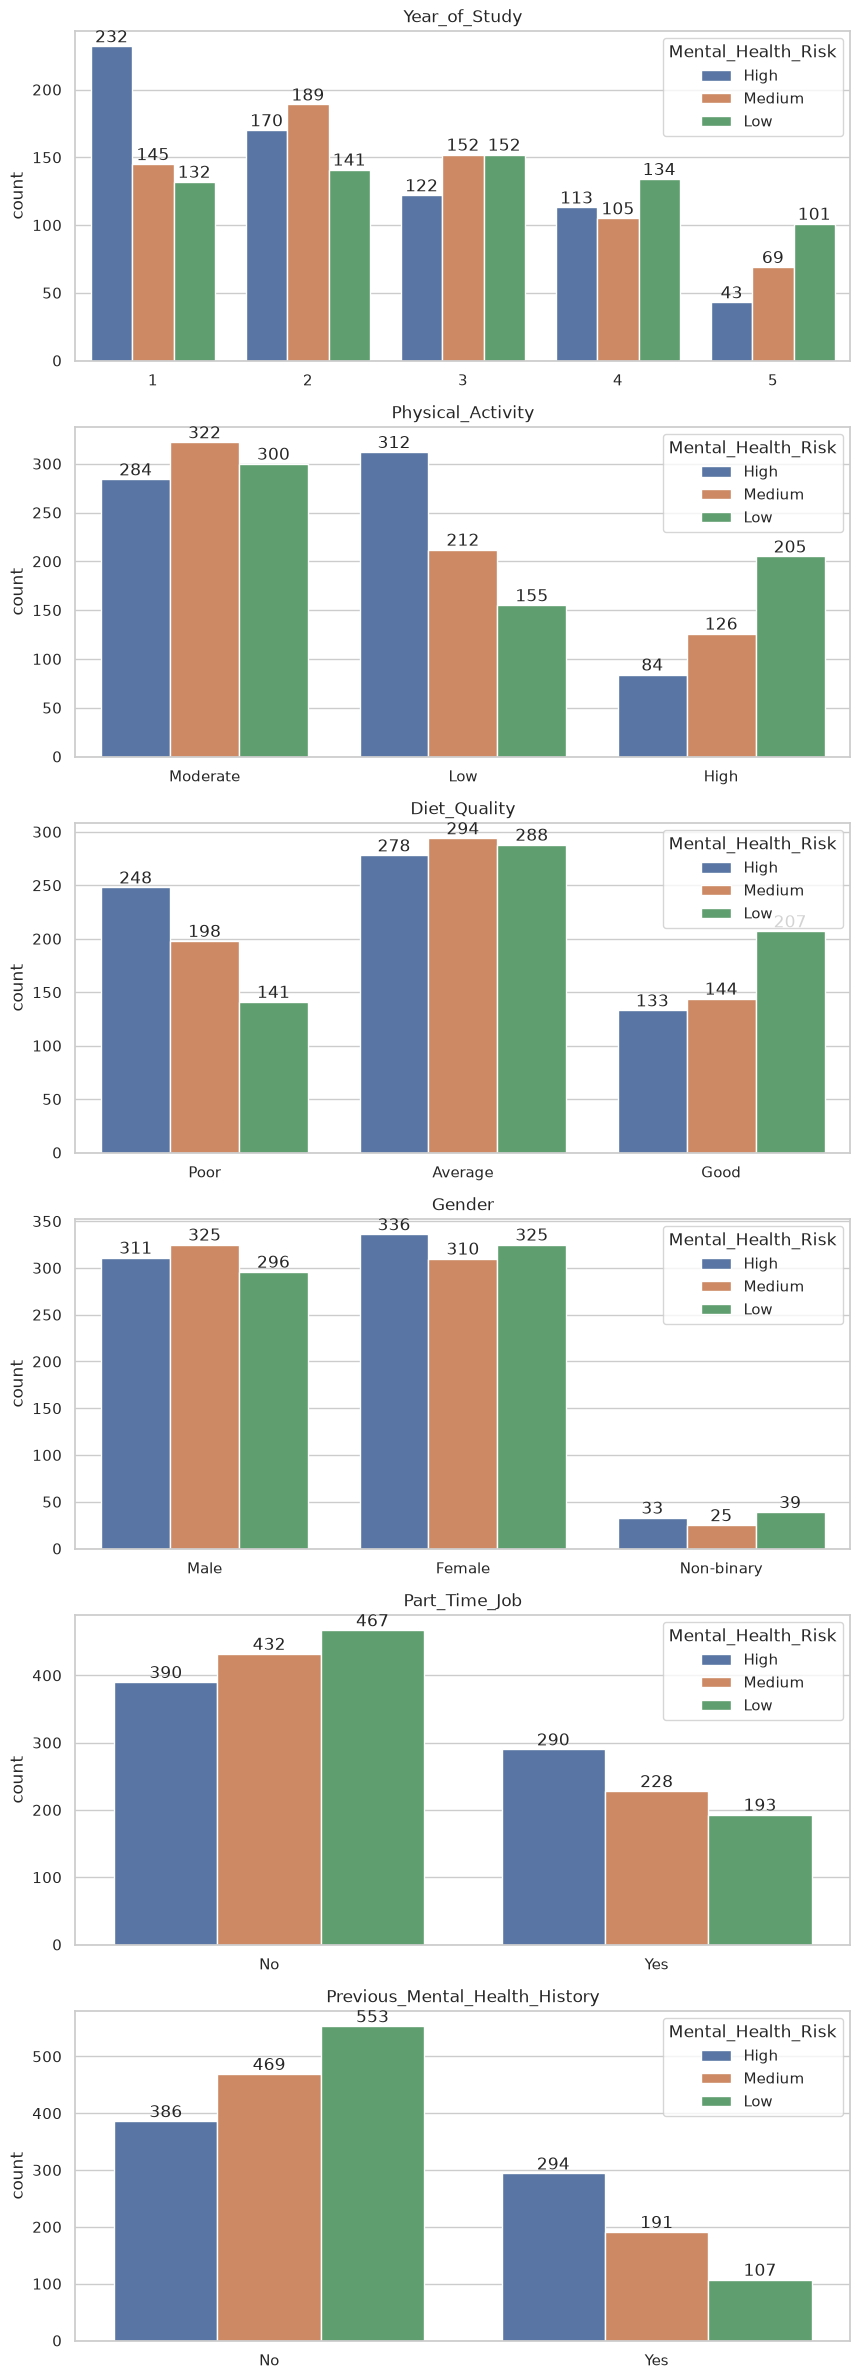

In [33]:
CATEGORICAL_COLS = ORDINAL_COLS + NOMINAL_COLS
_, axes = plt.subplots(nrows=len(CATEGORICAL_COLS), ncols=1, figsize=(10, 5 * len(CATEGORICAL_COLS)))

for axe , col in zip(axes, CATEGORICAL_COLS):
    ax = sns.countplot(data=df, x=col, ax=axe, hue='Mental_Health_Risk')
    axe.set_title(col)
    axe.set_xlabel('')
    for container in ax.containers:
        ax.bar_label(container, fmt='%d')

plt.show()

## 4 - Analyse des relations entre Features et Target

#### 4-1 Variables numériques vs Target (Analyse multivariée)

=== Age ===


,count,mean,median,std
Mental_Health_Risk,,,,
High,680,21.138235,21.0,2.137748
Low,660,21.112121,21.0,2.115663
Medium,660,21.143939,21.0,2.167257


=== Sleep_Hours ===


,count,mean,median,std
Mental_Health_Risk,,,,
High,658,6.035258,6.1,0.948155
Low,647,7.523648,7.6,0.969303
Medium,633,6.729384,6.7,0.923886


=== Study_Hours_Per_Week ===


,count,mean,median,std
Mental_Health_Risk,,,,
High,680,18.362794,18.00,5.516742
Low,660,21.699697,21.70,5.663958
Medium,660,19.980758,20.15,5.488549


... (8 outputs left out)

=== Family_Support ===


,count,mean,median,std
Mental_Health_Risk,,,,
High,660,5.956212,5.90,1.861145
Low,640,7.088438,7.40,1.657512
Medium,646,6.527864,6.65,1.831413


=== Attendance_Rate ===


,count,mean,median,std
Mental_Health_Risk,,,,
High,666,83.767117,83.85,7.391075
Low,641,86.332293,86.60,6.930048
Medium,646,85.191641,85.35,7.114296


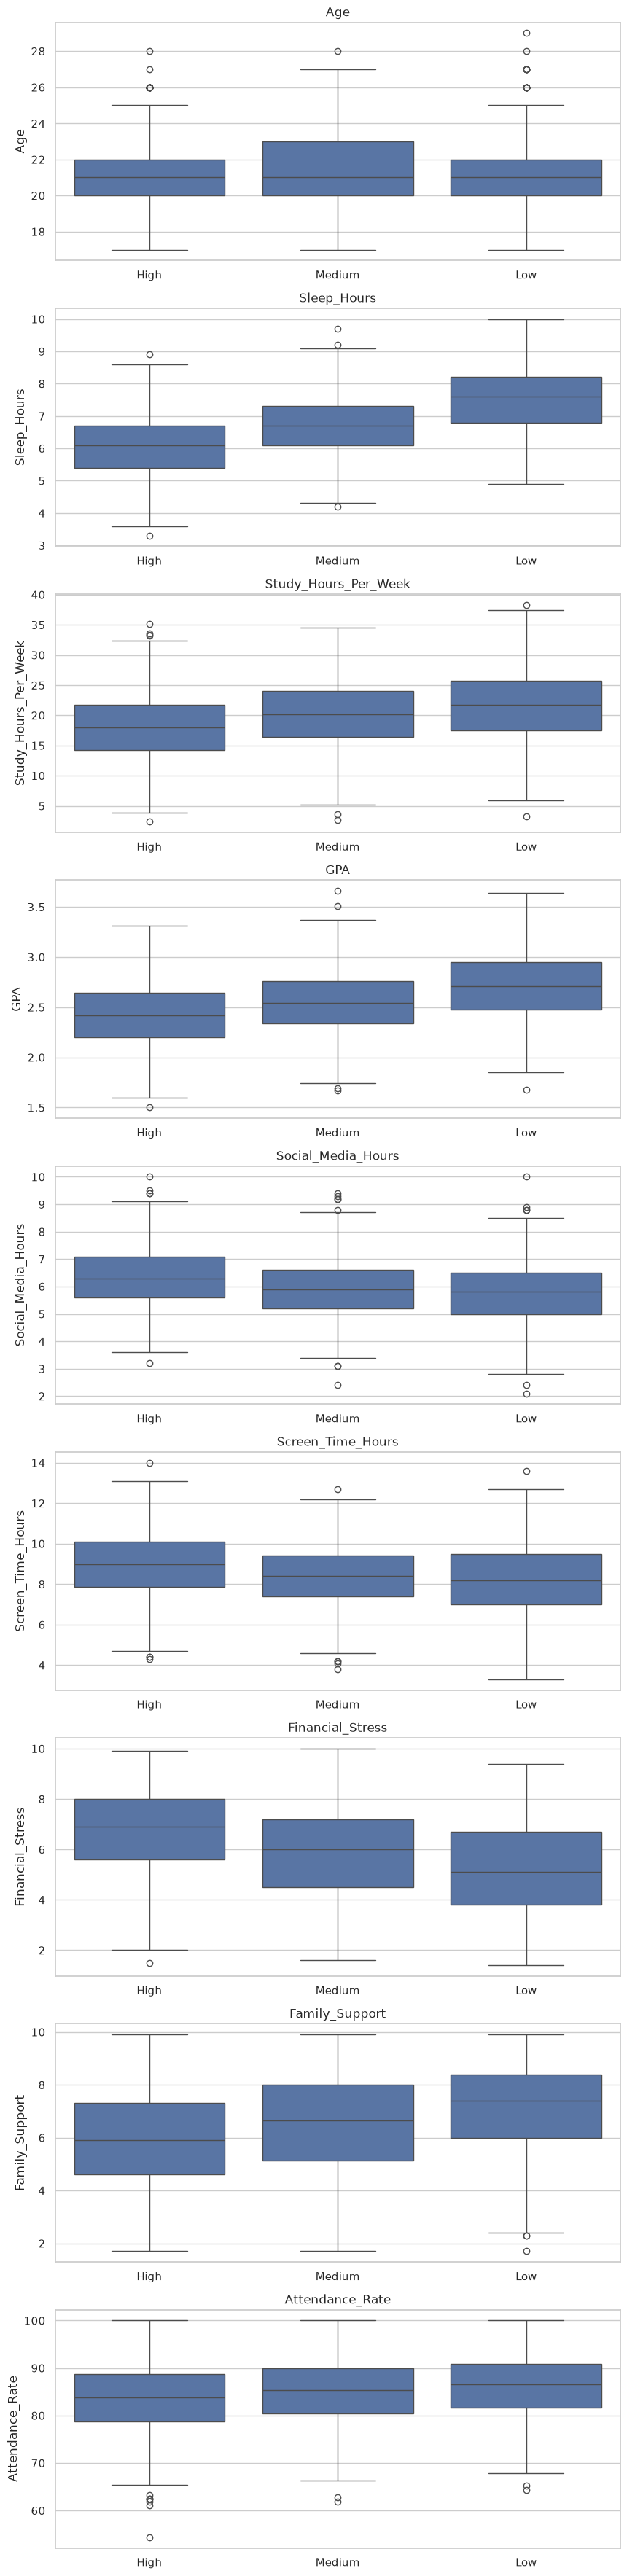

In [34]:
_, axes = plt.subplots(nrows=len(NUMERIC_COLS), ncols=1, figsize=(10, 5 * len(NUMERIC_COLS)))

for ax, col in zip(axes, NUMERIC_COLS):
    # State
    print(f'=== {col} ===')
    col_state = df.groupby('Mental_Health_Risk')[col].agg(["count", 'mean', 'median', 'std'])
    display(col_state)

    # Boxplot
    sns.boxplot(data=df, x='Mental_Health_Risk', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')

plt.show()

#### 4-2 Variables catégorielles vs Target (Analyse multivariée)

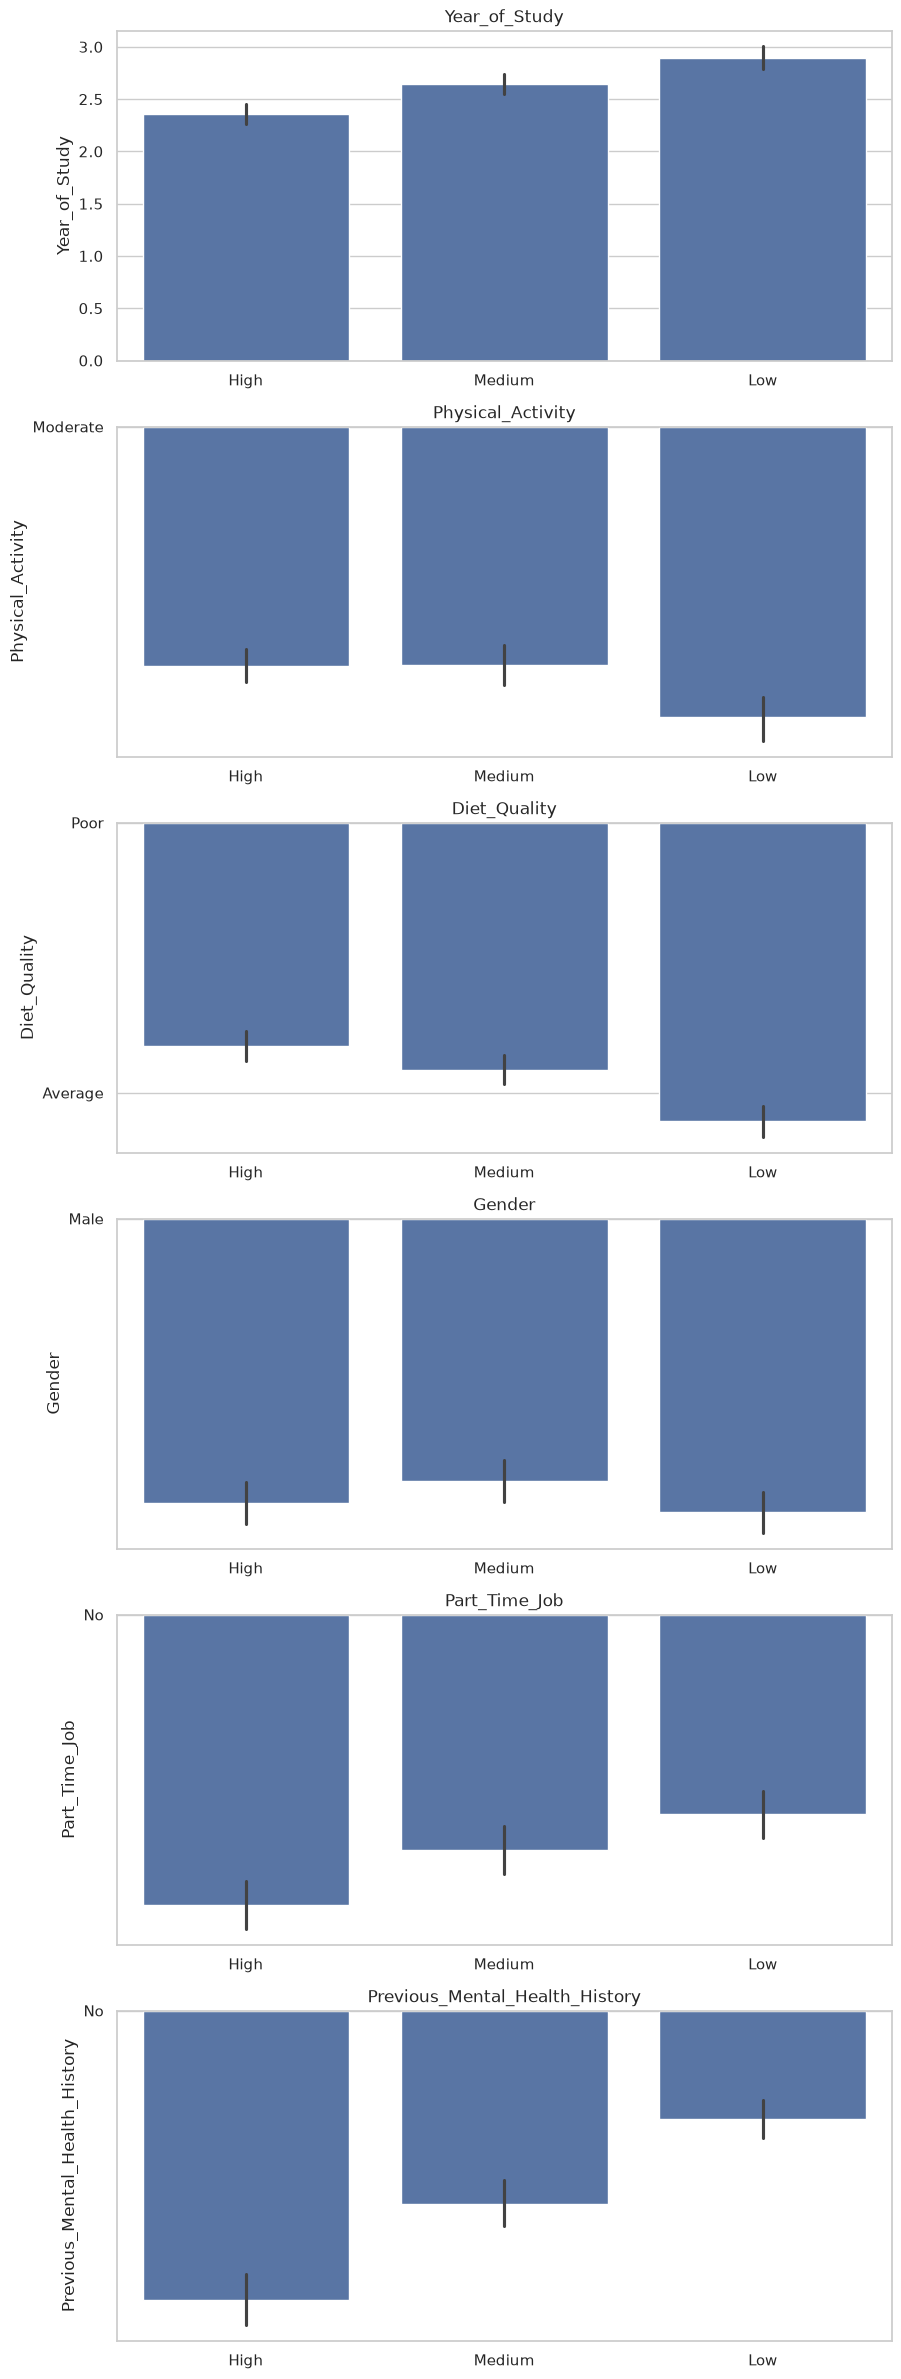

In [35]:
_, axes = plt.subplots(nrows=len(CATEGORICAL_COLS), ncols=1, figsize=(10, 5 * len(CATEGORICAL_COLS)))

for axe, col in zip(axes, CATEGORICAL_COLS):
    # Boxplot
    sns.barplot(data=df, x='Mental_Health_Risk', y=col, ax=axe)
    axe.set_title(col)
    axe.set_xlabel('')

plt.show()

## 5 - Examiner les corrélations

#### 5-1 Matrice de corrélation - Variables numériques

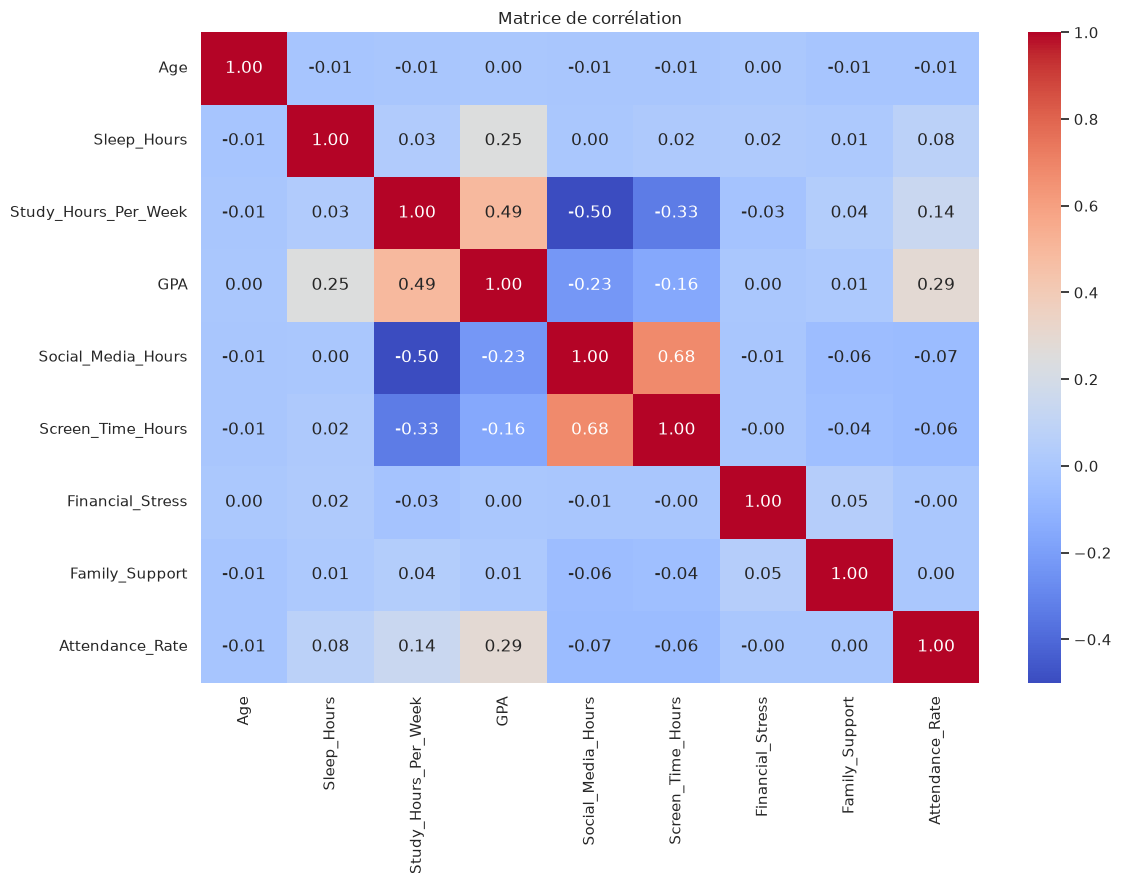

In [36]:
corr_matrix = df[NUMERIC_COLS].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
)

plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

#### 5-2 Exemples

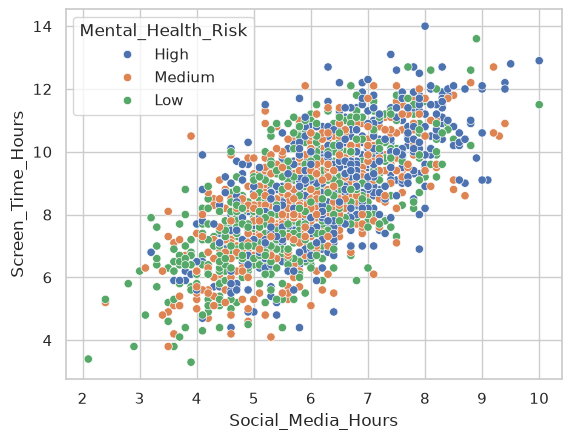

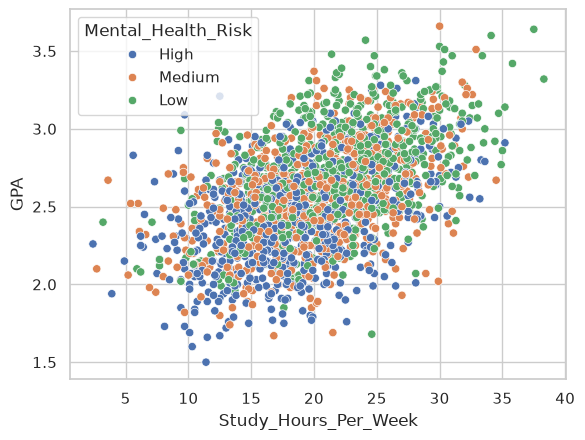

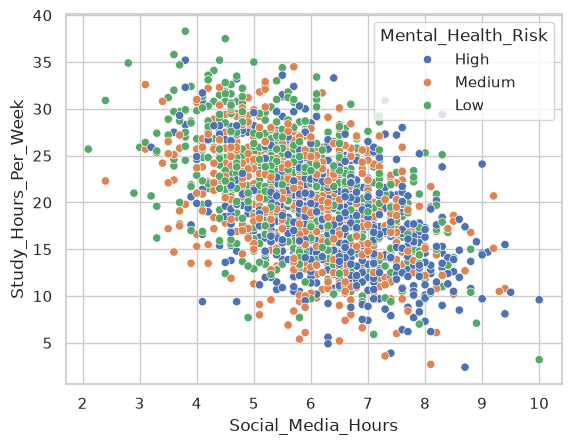

In [37]:
def figure_scatterplot(df:pd.DataFrame, x:str, y:str, hue:str = 'Mental_Health_Risk'):
    plt.figure()
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        hue=hue,
    )
    plt.show()

figure_scatterplot(df, x="Social_Media_Hours", y="Screen_Time_Hours")

figure_scatterplot(df, x="Study_Hours_Per_Week", y="GPA")

figure_scatterplot(df, x="Social_Media_Hours", y="Study_Hours_Per_Week")


# Étape 2 - Transformation et préparation des données (Preprocessing)

#### 1 - Diviser les données

In [38]:
X = df.drop(columns=['Mental_Health_Risk', 'Student_ID'])
y = df['Mental_Health_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_KEY
)

print("Train :", X_train.shape)
print("Test :", X_test.shape)

Train : (1600, 15)
Test : (400, 15)


#### 2 - Création du Pipeline complet et regrouper avec ColumnTransformer

In [39]:
def generate_preprocessor(num_cols:list, nom_cols:list, ord_cols:list, is_apply_scaler:bool = True):
    # Pipeline numérique
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('outliers', IQRCapper()),
    ]

    numeric_pipeline = Pipeline([

        ("scaler", StandardScaler() if is_apply_scaler else "passthrough")
    ])

    # Pipeline nominal
    nominal_pipline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Pipeline ordinal
    ordinal_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            categories=[
                ["Low", "Moderate", "High"],
                ["Poor", "Average", "Good"]
            ]
        ))
    ])

    # remove Year_of_Study from ordinal cols if exist
    if 'Year_of_Study' in ord_cols:
        ord_cols = [col for col in ord_cols if col != 'Year_of_Study']

    # column transformer
    return ColumnTransformer([
        ('num', numeric_pipeline, num_cols),
        ('nom', nominal_pipline, nom_cols),
        ('ord', ordinal_pipeline, ord_cols)
    ])

#### 3 - Fix social media hours

In [40]:
def fix_social_media(X):
    X = X.copy()
    X['Social_Media_Hours'] = X['Social_Media_Hours'].clip(upper=X['Screen_Time_Hours'])
    return X

social_media_transformer = FunctionTransformer(fix_social_media)

#### 4 - Appliquer les transformations

In [41]:
preprocessor = generate_preprocessor(NUMERIC_COLS, NOMINAL_COLS, ORDINAL_COLS)

X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

X_fixed = fix_social_media(X)

print(
    "Avant :",
    (X_train["Social_Media_Hours"] >
     X_train["Screen_Time_Hours"]).sum()
)

print(
    "Après :",
    (X_fixed["Social_Media_Hours"] >
     X_fixed["Screen_Time_Hours"]).sum()
)

print("Train :", X_train_prepared.shape)
print("Test :", X_test_prepared.shape)

Avant : 31
Après : 0
Train : (1600, 18)
Test : (400, 18)


#### 6 - Gérer le déséquilibre des classes — SMOTE

In [42]:
# from imblearn.over_sampling import SMOTE
# from imblearn.pipeline import Pipeline as ImbPipeline
#
# sm = SMOTE(random_state=RANDOM_KEY)
# X_res, y_res = sm.fit_resample(X, y)

# Étape 3 — Entraînement et comparaison des modèles de classification

#### 1 - Préparer les modèles

In [43]:
def build_model(model, is_apply_scaler:bool = True):
    pipeline = Pipeline([
        ('fix_social_media', social_media_transformer),
        ('preprocessing', generate_preprocessor(NUMERIC_COLS, NOMINAL_COLS, ORDINAL_COLS, is_apply_scaler)),
        ('classifier', model)
    ])

    return pipeline

models = {
    "Logistic Regression": build_model(LogisticRegression(max_iter=1000)),
    "KNN": build_model(KNeighborsClassifier(n_neighbors=4)),
    "Random Forest": build_model(RandomForestClassifier(random_state=42), is_apply_scaler=False)
}

#### 2 - Entraîner

                 model  Accuracy  Precision    Recall  F1-score
0  Logistic Regression    0.7425   0.744229  0.742276  0.743044
1                  KNN    0.5925   0.580578  0.591578  0.583387
2        Random Forest    0.7150   0.710491  0.714424  0.711265


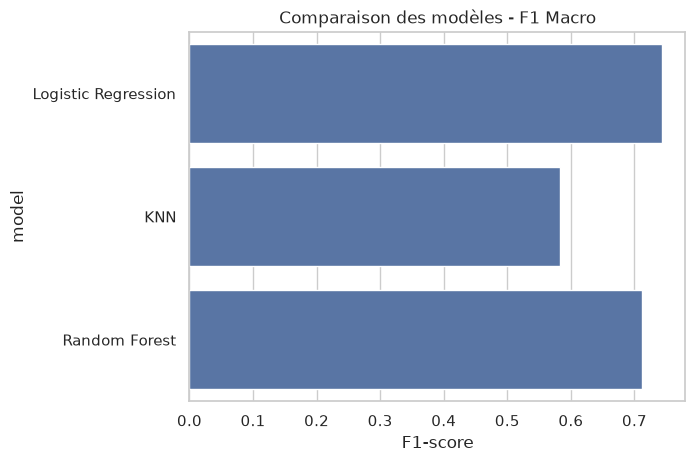

In [46]:
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        "model": name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro'),
        'Recall': recall_score(y_test, y_pred, average='macro'),
        'F1-score': f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results)

print(results_df)

# Visualisation
sns.barplot(data=results_df, x='F1-score', y='model')
plt.title("Comparaison des modèles - F1 Macro")
plt.show()

#### 3 - Matrice de confusion